# P3 Movie Genre — Notebook 2: Vectorization, Modeling & LLM Distillation

**Goal:** turn plot text into features, train one class-weighted logistic regression per selected genre, then measure how much accuracy is lost when an LLM teacher replaces IMDB as the source of training labels.

| Step | Contents |
|---|---|
| 1 | Setup: vote filter, train (train + val) / test split |
| 2 | Selected genres and their positive rates |
| 3 | Representations: TF-IDF and a sentence-embedding model, standardized |
| 4–5 | Class-weight grid search, test-set evaluation |
| 6–7 | LLM teacher pseudo-labels a ≤ 300-plot training sample; teacher accuracy |
| 8 | Student models trained on pseudo-labels |
| 9 | Leaderboard |
| 10 | Export models, vectorizer and scaler to `models/` |

Every model is logistic regression, so the **representation** and the **label source** are the only things that change between rows of the leaderboard.

In [42]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import ollama
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

DATA_PATH = Path("../data/mpst_imdb_movies.csv")
PSEUDO_PATH = Path("../data/pseudo_labeled.csv")
MODELS_DIR = Path("../models")
CACHE_DIR = Path.home() / ".cache" / "msds565_p3"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

VOTE_MIN = 1000          # chosen in Notebook 1, section 1.3
RANDOM_STATE = 42

**Paths.** The dataset and the exported `pseudo_labeled.csv` live in the git-ignored `data/` folder, so neither is committed. The embedding cache goes **outside the repo** in `~/.cache/msds565_p3`, as required. Only the trained models go into `models/`.

## 1. Setup
Apply Notebook 1's vote filter. Then use MPST's own `split` column: **training = train + val**, **test = test**. The only feature is `plot_synopsis`; the IMDB metadata is not used from here on.

In [43]:
df = pd.read_csv(DATA_PATH)
df["numVotes"] = pd.to_numeric(df["numVotes"], errors="coerce")
df = df[df["numVotes"] >= VOTE_MIN].reset_index(drop=True)

train_df = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)
print(f"train: {len(train_df):,}   test: {len(test_df):,}")

train: 9,996   test: 2,526


## 2. Selected genres
**Our picks: Comedy, Horror, Romance.**

- **They're our favorites**, and they're also three very different kinds of story: jokes and misadventure, fear and the supernatural, relationships and courtship.
- **They should have clearly different vocabularies** (Notebook 1 §3.2), which makes the TF-IDF coefficients in Notebook 3 easy to read.
- **They overlap in useful ways.** Romantic comedies sit between Comedy and Romance, and horror-comedies between Comedy and Horror. This gives the LLM teacher realistic ambiguous cases to label.

Each genre must have at least 5% positives in both sets. The cell below verifies this.

In [44]:
GENRES = ["Comedy", "Horror", "Romance"]


def slug(genre):
    return genre.lower().replace("-", "")


rates = pd.DataFrame({
    "train_pos": train_df[GENRES].sum(), "train_rate": train_df[GENRES].mean(),
    "test_pos": test_df[GENRES].sum(), "test_rate": test_df[GENRES].mean(),
})
assert (rates[["train_rate", "test_rate"]] >= 0.05).all().all(), "a selected genre is below 5% positives"
rates

,train_pos,train_rate,test_pos,test_rate
Comedy,3165,0.317,767,0.304
Horror,1758,0.176,465,0.184
Romance,1701,0.170,424,0.168


## 3. Text representations

### 3.1 TF-IDF
Settings and the reasoning behind each:
- **Unigrams only**, letters only, 3+ characters. Notebook 3 explains the model one coefficient per *word*, so bigrams and numbers would muddy that.
- **`stop_words="english"`**. Function words carry no genre signal.
- **`min_df=5`** drops typos and one-off names. **`max_df=0.8`** drops words in almost every synopsis.
- **`max_features=10000`** keeps the vocabulary manageable. It also keeps Notebook 3's SHAP matrix (test rows × features) in memory.
- **`sublinear_tf=True`** dampens repetition. A name mentioned 30 times shouldn't count 30× more than one mentioned once.

The vectorizer is fit on the training set only.

In [45]:
tfidf = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
                        min_df=5, max_df=0.8, max_features=10000, sublinear_tf=True)
Xtr_tfidf_raw = tfidf.fit_transform(train_df["plot_synopsis"])
Xte_tfidf_raw = tfidf.transform(test_df["plot_synopsis"])
print(f"TF-IDF vocabulary: {len(tfidf.vocabulary_):,} words")

TF-IDF vocabulary: 10,000 words


### 3.2 Sentence embeddings
**Model: `sentence-transformers/all-MiniLM-L6-v2`, 384 dimensions.**

Why this model: it's small (22M parameters) and runs on a laptop CPU in minutes. It's one of the most widely used general-purpose sentence encoders, trained contrastively on over a billion sentence pairs. And because it's small, we can afford to embed every synopsis in full, rather than only the first few hundred words.

**Long synopses.** MiniLM reads at most 256 word-pieces and silently drops the rest, but many synopses are far longer (Notebook 1 §3.1). So each synopsis is split into **180-word chunks** (≈ 240 word-pieces, just under the limit). Each chunk is embedded, and the unit-normalized chunk vectors are averaged into one 384-d document vector. This way the ending of a plot (often the most genre-revealing part) still counts.

**Caching.** Embedding the whole corpus takes a while, so the matrix is computed once and saved to `~/.cache/msds565_p3` (outside the repo) along with each row's `imdb_id`. Later runs load it and look rows up by ID, so the cached rows can't silently fall out of alignment with the data.

In [46]:
EMB_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
EMB_SHORT = "emb-minilm"
CHUNK_WORDS = 180
emb_cache = CACHE_DIR / f"{EMB_SHORT}_chunk{CHUNK_WORDS}_votes{VOTE_MIN}.npz"


def embed_documents(texts, model):
    pieces, owner = [], []
    for i, text in enumerate(texts):
        words = text.split()
        chunks = [" ".join(words[j:j + CHUNK_WORDS]) for j in range(0, len(words), CHUNK_WORDS)] or [""]
        pieces.extend(chunks)
        owner.extend([i] * len(chunks))
    vecs = model.encode(pieces, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    owner = np.array(owner)
    doc_vecs = np.zeros((len(texts), vecs.shape[1]), dtype=np.float32)
    np.add.at(doc_vecs, owner, vecs)
    return doc_vecs / np.bincount(owner, minlength=len(texts))[:, None]


if emb_cache.exists():
    cached = np.load(emb_cache)
    emb_lookup = pd.DataFrame(cached["E"], index=cached["ids"])
    print(f"Loaded cached embeddings from {emb_cache}")
else:
    start = time.time()
    E = embed_documents(df["plot_synopsis"].tolist(), SentenceTransformer(EMB_MODEL_ID))
    np.savez_compressed(emb_cache, ids=df["imdb_id"].to_numpy(dtype=str), E=E)
    emb_lookup = pd.DataFrame(E, index=df["imdb_id"].to_numpy(dtype=str))
    print(f"Embedded {len(df):,} synopses in {time.time() - start:.0f}s; cached to {emb_cache}")

Xtr_emb_raw = emb_lookup.loc[train_df["imdb_id"]].to_numpy()
Xte_emb_raw = emb_lookup.loc[test_df["imdb_id"]].to_numpy()
print(f"Embedding dimensionality: {Xtr_emb_raw.shape[1]}")

Loaded cached embeddings from /Users/treyagee/.cache/msds565_p3/emb-minilm_chunk180_votes1000.npz
Embedding dimensionality: 384


### 3.3 Standardization
Both representations are standardized with `StandardScaler`, **fit on the training set only**. TF-IDF uses `with_mean=False`, since subtracting the mean would turn the sparse matrix dense. After scaling, every feature has unit variance, so coefficient sizes are comparable across words (Notebook 3 relies on this).

In [47]:
tfidf_scaler = StandardScaler(with_mean=False).fit(Xtr_tfidf_raw)
emb_scaler = StandardScaler().fit(Xtr_emb_raw)

REPS = {
    "tfidf": (tfidf_scaler.transform(Xtr_tfidf_raw), tfidf_scaler.transform(Xte_tfidf_raw)),
    EMB_SHORT: (emb_scaler.transform(Xtr_emb_raw), emb_scaler.transform(Xte_emb_raw)),
}

## 4. Class-weighted logistic regression
Imbalance is handled with **class weights only** (no resampling). For each representation × genre, `GridSearchCV` with 5-fold **stratified** CV and `scoring="f1_macro"` picks among five settings: `None`, `"balanced"`, and `{0: 1, 1: w}` for w = 2, 4, 8. The fixed weights span from mild up-weighting to roughly the inverse class ratio of a ~12% genre. `"balanced"` sets that ratio automatically.

Macro-F1 averages the F1 of the positive and negative class. This rewards a model that finds the minority genre without giving up on the majority class, unlike accuracy, which a model can score well on by always predicting "no".

**Fixed hyperparameters.** Only `class_weight` is searched, so the grid isolates the effect of the weighting. `C=0.1` is held fixed: with 10,000 standardized features (each at unit variance), the default `C=1` gives too little regularization and lets rare words take on huge weights. The `liblinear` solver is efficient for binary problems on sparse data.

The same helper is reused in step 8 for the pseudo-labeled models.

In [48]:
CW_GRID = [None, "balanced", {0: 1, 1: 2}, {0: 1, 1: 4}, {0: 1, 1: 8}]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = {}     # (label_source, rep, genre) -> fitted model and test-set predictions
cv_tables = {}   # (label_source, rep, genre) -> "mean ± std" macro-F1 per class_weight


def fit_and_score(source, rep, X_fit, y_fit, X_test, genre):
    gs = GridSearchCV(LogisticRegression(C=0.1, solver="liblinear", max_iter=2000, random_state=RANDOM_STATE),
                      {"class_weight": CW_GRID}, cv=CV, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_fit, y_fit)
    cv = pd.DataFrame(gs.cv_results_)
    cv_tables[(source, rep, genre)] = pd.Series(
        [f"{m:.3f} ± {s:.3f}" for m, s in zip(cv["mean_test_score"], cv["std_test_score"])],
        index=[str(params["class_weight"]) for params in cv["params"]])
    model = gs.best_estimator_
    y_pred = model.predict(X_test)
    results[(source, rep, genre)] = {
        "model": model,
        "best_cw": str(gs.best_params_["class_weight"]),
        "y_pred": y_pred,
        "f1": f1_score(test_df[genre], y_pred, average="macro"),
    }


def show_cv(source):
    table = pd.DataFrame({f"{rep} · {g}": cv_tables[(source, rep, g)] for rep in REPS for g in GENRES})
    table.loc["→ best"] = [results[(source, rep, g)]["best_cw"] for rep in REPS for g in GENRES]
    table.index.name = "class_weight"
    return table

In [49]:
start = time.time()
for rep, (Xtr, Xte) in REPS.items():
    for g in GENRES:
        fit_and_score("IMDB", rep, Xtr, train_df[g].to_numpy(), Xte, g)
print(f"Grid searches finished in {time.time() - start:.0f}s")
show_cv("IMDB")

Grid searches finished in 58s


,tfidf · Comedy,tfidf · Horror,tfidf · Romance,emb-minilm · Comedy,emb-minilm · Horror,emb-minilm · Romance
class_weight,,,,,,
None,0.746 ± 0.002,0.844 ± 0.011,0.701 ± 0.008,0.740 ± 0.009,0.830 ± 0.010,0.739 ± 0.009
balanced,0.745 ± 0.002,0.848 ± 0.011,0.705 ± 0.006,0.741 ± 0.008,0.800 ± 0.008,0.715 ± 0.007
"{0: 1, 1: 2}",0.745 ± 0.002,0.846 ± 0.011,0.701 ± 0.005,0.745 ± 0.009,0.835 ± 0.007,0.747 ± 0.006
"{0: 1, 1: 4}",0.741 ± 0.003,0.846 ± 0.010,0.703 ± 0.007,0.700 ± 0.005,0.811 ± 0.007,0.730 ± 0.003
"{0: 1, 1: 8}",0.739 ± 0.005,0.849 ± 0.008,0.704 ± 0.007,0.612 ± 0.004,0.770 ± 0.009,0.677 ± 0.006
→ best,None,"{0: 1, 1: 8}",balanced,"{0: 1, 1: 2}","{0: 1, 1: 2}","{0: 1, 1: 2}"


The table above shows the 5-fold CV macro-F1 (mean ± std) for every class-weight setting. The last row shows the setting each model kept. Each best model is then evaluated **once** on the test set below.

**TODO (write after running):** did up-weighting the positive class beat `None`? Was the best setting similar across the two representations? Are the CV standard deviations small enough that the winner is a real improvement rather than noise?

## 5. Evaluation on the test set
A classification report and confusion heatmap for every representation × genre. The plotting helper is shared with step 8.

In [50]:
def report(source):
    for rep in REPS:
        for g in GENRES:
            print(f"=== {source} labels · {rep} · {g} ===")
            print(classification_report(test_df[g], results[(source, rep, g)]["y_pred"],
                                        target_names=[f"not {g}", g], digits=3))


def plot_confusions(source):
    fig, axes = plt.subplots(len(REPS), len(GENRES), figsize=(4.2 * len(GENRES), 3.8 * len(REPS)))
    for i, rep in enumerate(REPS):
        for j, g in enumerate(GENRES):
            r = results[(source, rep, g)]
            sns.heatmap(confusion_matrix(test_df[g], r["y_pred"]), annot=True, fmt="d", cmap="Blues",
                        cbar=False, ax=axes[i, j], xticklabels=["no", "yes"], yticklabels=["no", "yes"])
            axes[i, j].set(title=f"{rep} · {g}\nmacro-F1 = {r['f1']:.3f}", xlabel="Predicted", ylabel="True")
    fig.suptitle(f"Test-set confusion matrices — trained on {source} labels", y=1.01)
    plt.tight_layout()
    plt.show()


report("IMDB")

=== IMDB labels · tfidf · Comedy ===
              precision    recall  f1-score   support

  not Comedy      0.832     0.864     0.847      1759
      Comedy      0.657     0.600     0.627       767

    accuracy                          0.783      2526
   macro avg      0.745     0.732     0.737      2526
weighted avg      0.779     0.783     0.781      2526

=== IMDB labels · tfidf · Horror ===
              precision    recall  f1-score   support

  not Horror      0.944     0.942     0.943      2061
      Horror      0.745     0.753     0.749       465

    accuracy                          0.907      2526
   macro avg      0.844     0.847     0.846      2526
weighted avg      0.907     0.907     0.907      2526

=== IMDB labels · tfidf · Romance ===
              precision    recall  f1-score   support

 not Romance      0.909     0.890     0.899      2102
     Romance      0.505     0.557     0.530       424

    accuracy                          0.834      2526
   macro avg    

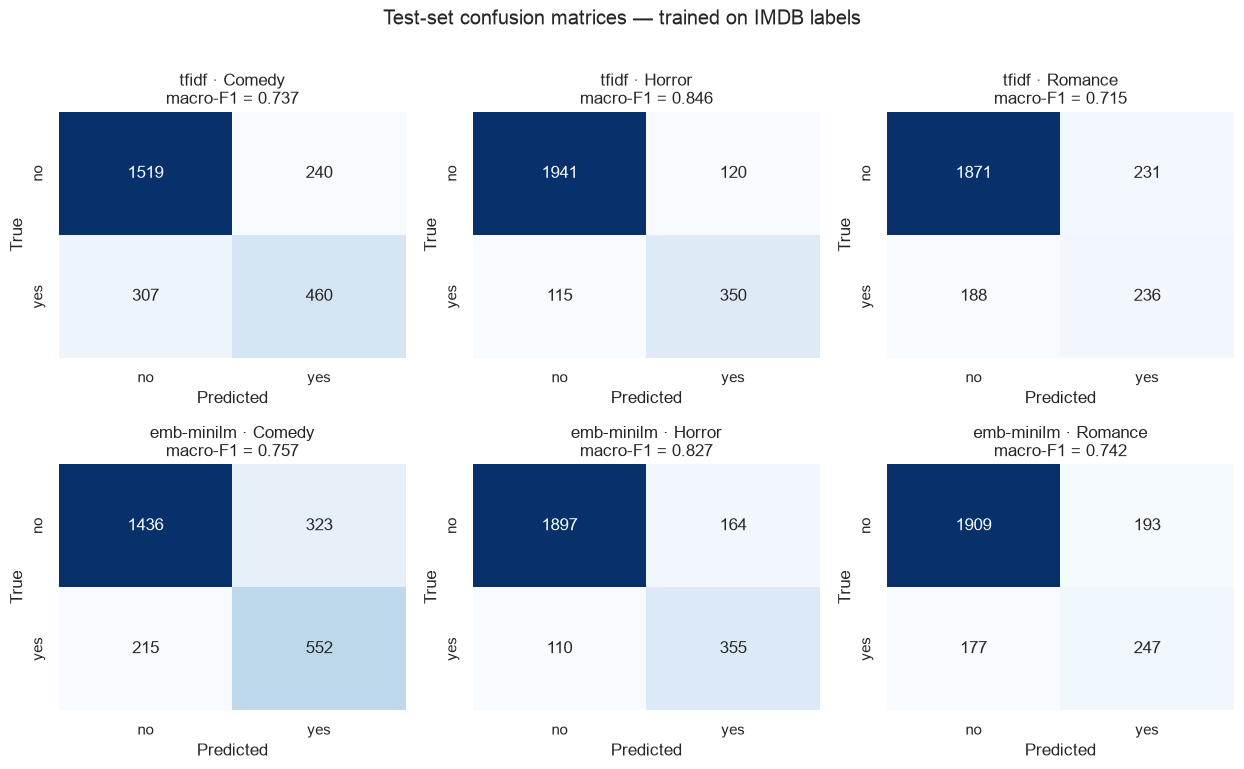

In [51]:
plot_confusions("IMDB")

**TODO (write after running):** which representation wins for each genre? Which genre is hardest (Romance and Comedy often blur together)? Do the errors lean toward false positives (from the up-weighted class) or false negatives?

## 6. Teacher annotation (pseudo-labeling)
Now pretend IMDB's genre labels don't exist for the training set. An LLM teacher reads a sample of training plots and labels them. A cheap logistic-regression student then learns from those noisy labels.

**Teacher: `llama3.1:8b`** (Meta Llama 3.1, 8B instruct, Q4 quantization), run locally through the **Ollama** Python SDK. Setup: `ollama pull llama3.1:8b`. We chose a local model because it's free, the same weights give the same answers on every run, and no plot text leaves the machine. It also natively supports structured output through a JSON schema.

**Deterministic settings:** `temperature=0` and a fixed `seed`, so a rerun reproduces the same labels.

### 6.1 The sample
For each genre, draw 100 training-set plots *in that genre* (`random_state=42`), then combine and drop duplicates. The teacher sees **only** these training plots, never the test set. Because the sample is drawn from genre positives, its positive rates are far higher than in the full training set. We keep this in mind when reading the teacher's precision and recall.

In [52]:
sample = (pd.concat([train_df[train_df[g] == 1].sample(100, random_state=RANDOM_STATE) for g in GENRES])
            .drop_duplicates("imdb_id")
            .reset_index(drop=True))
print(f"Teacher sample: {len(sample)} unique training plots")
sample[GENRES].mean().rename("positive rate in sample").to_frame().T

Teacher sample: 295 unique training plots


,Comedy,Horror,Romance
positive rate in sample,0.542,0.386,0.424


### 6.2 Prompt and schema
- **One call per movie**, asking about all three genres at once.
- The prompt contains the **plot text and the genre names only, never the title**. If the model recognized a film, it could recall its genres from memory instead of reading the plot.
- A short definition of each genre steers the teacher toward IMDB's meaning of the label. For example, a dark film with a single romantic subplot isn't a Romance.
- The **JSON schema** has exactly one required boolean per genre and `"additionalProperties": false`, so the reply can neither skip a genre nor invent one. Ollama enforces the schema while generating (constrained decoding), and `json.loads` parses the result.

**Truncation:** plots are cut at **8,000 characters** (≈ 2,000 tokens), backed up to the last full sentence. Together with the instructions, this fits comfortably inside the `num_ctx=4096` window we set, which keeps an 8B model fast on a laptop. The opening sections of a synopsis establish the setting, tone and premise, which is usually enough to judge genre. The cell below reports how many sample plots were cut.

In [53]:
MAX_CHARS = 3000
TEACHER_MODEL = "llama3.2:3b"

GENRE_DEFINITIONS = {
    "Comedy": "the story is primarily meant to be funny: humor, comic misadventures, satire or farce",
    "Horror": "the story is primarily meant to frighten: monsters, the supernatural, killers stalking victims, dread",
    "Romance": "a love story between characters is a central plot line, not just a side detail",
}

SCHEMA = {
    "type": "object",
    "properties": {g: {"type": "boolean"} for g in GENRES},
    "required": GENRES,
    "additionalProperties": False,
}

SYSTEM_PROMPT = (
    "You are an expert film genre annotator. Read a movie plot synopsis and decide, for each listed genre, "
    "whether the movie belongs to it. A movie can belong to several of the genres or to none. "
    "Judge only from the plot text.\n\nGenre definitions:\n"
    + "\n".join(f"- {g}: {d}" for g, d in GENRE_DEFINITIONS.items())
)


def truncate(text):
    if len(text) <= MAX_CHARS:
        return text
    cut = text[:MAX_CHARS]
    return cut[:cut.rfind(". ") + 1] or cut


def annotate(plot):
    reply = ollama.chat(
        model=TEACHER_MODEL,
        messages=[{"role": "system", "content": SYSTEM_PROMPT},
                  {"role": "user", "content": f"Genres: {', '.join(GENRES)}\n\nPlot synopsis:\n{truncate(plot)}\n\n"
                                              "Answer with one true/false field per genre."}],
        format=SCHEMA,
        options={"temperature": 0, "seed": RANDOM_STATE, "num_ctx": 2048, "num_gpu": 0},
    )
    return json.loads(reply["message"]["content"])


print(f"{(sample['plot_synopsis'].str.len() > MAX_CHARS).sum()} of {len(sample)} sample plots truncated to {MAX_CHARS:,} characters")

200 of 295 sample plots truncated to 3,000 characters


### 6.3 Run the teacher and save `pseudo_labeled.csv`
The teacher is slow and its output is the input to step 8. So its labels are saved to `data/pseudo_labeled.csv` (git-ignored) and reloaded on later runs. The assertion checks that a reloaded file belongs to this exact sample.

In [54]:
def pred_col(genre):
    return f"pred_{slug(genre)}"


if PSEUDO_PATH.exists():
    pseudo = pd.read_csv(PSEUDO_PATH)
    print(f"Loaded cached teacher labels from {PSEUDO_PATH}")
else:
    start = time.time()
    labels = [annotate(plot) for plot in sample["plot_synopsis"]]
    pseudo = sample[["imdb_id", "primaryTitle", "plot_synopsis"]].copy()
    for g in GENRES:
        pseudo[pred_col(g)] = [int(lab[g]) for lab in labels]
    pseudo.to_csv(PSEUDO_PATH, index=False)
    print(f"Annotated {len(pseudo)} plots in {time.time() - start:.0f}s; saved to {PSEUDO_PATH}")

assert pseudo["imdb_id"].tolist() == sample["imdb_id"].tolist(), "pseudo_labeled.csv is from a different sample"
pseudo[[pred_col(g) for g in GENRES]].mean().rename("teacher positive rate").to_frame().T

Annotated 295 plots in 2282s; saved to ../data/pseudo_labeled.csv


,pred_comedy,pred_horror,pred_romance
teacher positive rate,0.332,0.261,0.21


## 7. Teacher accuracy
The teacher's labels compared with the true IMDB labels on the same sample. Precision, recall and F1 are for the **positive** class of each genre. Macro-F1 is included as well, to match the leaderboard's metric.

In [55]:
rows = {}
for g in GENRES:
    y_true, y_teacher = sample[g], pseudo[pred_col(g)]
    p, r, f, _ = precision_recall_fscore_support(y_true, y_teacher, average="binary")
    rows[g] = {"precision": p, "recall": r, "F1": f, "macro-F1": f1_score(y_true, y_teacher, average="macro"),
               "true_pos_in_sample": int(y_true.sum()), "teacher_pos": int(y_teacher.sum())}
teacher_scores = pd.DataFrame(rows).T.astype({"true_pos_in_sample": int, "teacher_pos": int})
teacher_scores

,precision,recall,F1,macro-F1,true_pos_in_sample,teacher_pos
Comedy,0.959,0.588,0.729,0.759,160,98
Horror,0.987,0.667,0.796,0.849,114,77
Romance,0.774,0.384,0.513,0.644,125,62


Because the sample is small, we can look at the errors directly. Below are up to three disagreements per genre, each with the first 300 characters of the plot. (We see the title here; the teacher never did.)

In [56]:
for g in GENRES:
    wrong = sample[sample[g] != pseudo[pred_col(g)]]
    print(f"=== {g}: {len(wrong)} disagreements ===")
    for _, row in wrong.head(3).iterrows():
        verdict = "missed (false negative)" if row[g] == 1 else "added (false positive)"
        print(f"- {row['primaryTitle']} — teacher {verdict}\n  {row['plot_synopsis'][:300]}...")
    print()

=== Comedy: 70 disagreements ===
- Ninja in the Dragon's Den — teacher missed (false negative)
  In Japan of the Tokugawa Ieyasu period, a young ninja named Genbu wantonly kills samurai and other government officials, leaving his clan to face the blame. When they hunt him down, Genbu and his wife Akane sail to China both to escape their wrathful kinsmen and for Genbu to complete revenge by find...
- Murphy's Romance — teacher missed (false negative)
  After driving through the night in their pickup truck holding their life's belongings, divorced mother Emma Moriarty (Sally Field) and her son Jake (Corey Haim) arrive at their new home in Eunice, AZ. The property is a run-down ranch fixer-upper, so they resignedly set to work cleaning and repairing...
- Slashers — teacher missed (false negative)
  The latest craze is $la$her$, a Japanese blood sport game show where contestants can win millions of dollars if they survive being hunted through various arenas by costumed killers. All crimes 

**TODO (write after running):** which genre does the teacher label best and worst? Is it mostly over-labeling (low precision) or under-labeling (low recall)? Use the examples above to explain the patterns. For instance, IMDB may tag a film Comedy for a light tone that the plot summary never shows, or the teacher may call any love subplot Romance.

## 8. Training students on pseudo-labels
This repeats step 4 on the sample's rows, with the **teacher's labels as `y`**. It reuses step 3's fitted vectorizer and scalers, which never saw a label. The students are scored on the full test set against the **true IMDB labels**.

**Control (extra, clearly marked):** the student differs from the step-4 model in two ways at once: noisier labels *and* about 30× less data. To separate those effects, we also train on the **same sample with the true IMDB labels**. The gap between this control and the LLM-label student is the cost of label noise alone. The gap between the control and the full IMDB model is the cost of having less data.

In [57]:
rows_in_train = pd.Index(train_df["imdb_id"]).get_indexer(pseudo["imdb_id"])

start = time.time()
for rep, (Xtr, Xte) in REPS.items():
    X_sample = Xtr[rows_in_train]
    for g in GENRES:
        y_llm = pseudo[pred_col(g)].to_numpy()
        assert np.bincount(y_llm, minlength=2).min() >= 5, f"teacher labels for {g} are too one-sided for 5-fold CV"
        fit_and_score("LLM", rep, X_sample, y_llm, Xte, g)
        fit_and_score("IMDB-sample", rep, X_sample, sample[g].to_numpy(), Xte, g)
print(f"Grid searches finished in {time.time() - start:.0f}s")
show_cv("LLM")

Grid searches finished in 7s


,tfidf · Comedy,tfidf · Horror,tfidf · Romance,emb-minilm · Comedy,emb-minilm · Horror,emb-minilm · Romance
class_weight,,,,,,
None,0.581 ± 0.120,0.609 ± 0.094,0.503 ± 0.058,0.730 ± 0.036,0.741 ± 0.047,0.574 ± 0.080
balanced,0.627 ± 0.090,0.671 ± 0.108,0.503 ± 0.058,0.735 ± 0.027,0.751 ± 0.032,0.555 ± 0.058
"{0: 1, 1: 2}",0.627 ± 0.090,0.659 ± 0.113,0.503 ± 0.058,0.733 ± 0.026,0.737 ± 0.036,0.565 ± 0.054
"{0: 1, 1: 4}",0.669 ± 0.081,0.682 ± 0.121,0.503 ± 0.058,0.721 ± 0.026,0.746 ± 0.040,0.560 ± 0.053
"{0: 1, 1: 8}",0.737 ± 0.044,0.729 ± 0.103,0.516 ± 0.045,0.706 ± 0.026,0.747 ± 0.028,0.564 ± 0.058
→ best,"{0: 1, 1: 8}","{0: 1, 1: 8}","{0: 1, 1: 8}",balanced,balanced,None


CV macro-F1 above is measured against the teacher's own labels, so it shows how well the student imitates the teacher, not how accurate it is. The test-set results below compare against IMDB's labels.

In [58]:
report("LLM")

=== LLM labels · tfidf · Comedy ===
              precision    recall  f1-score   support

  not Comedy      0.787     0.887     0.834      1759
      Comedy      0.635     0.451     0.527       767

    accuracy                          0.755      2526
   macro avg      0.711     0.669     0.681      2526
weighted avg      0.741     0.755     0.741      2526

=== LLM labels · tfidf · Horror ===
              precision    recall  f1-score   support

  not Horror      0.898     0.962     0.929      2061
      Horror      0.752     0.516     0.612       465

    accuracy                          0.880      2526
   macro avg      0.825     0.739     0.771      2526
weighted avg      0.871     0.880     0.871      2526

=== LLM labels · tfidf · Romance ===
              precision    recall  f1-score   support

 not Romance      0.836     0.980     0.902      2102
     Romance      0.317     0.045     0.079       424

    accuracy                          0.823      2526
   macro avg      0

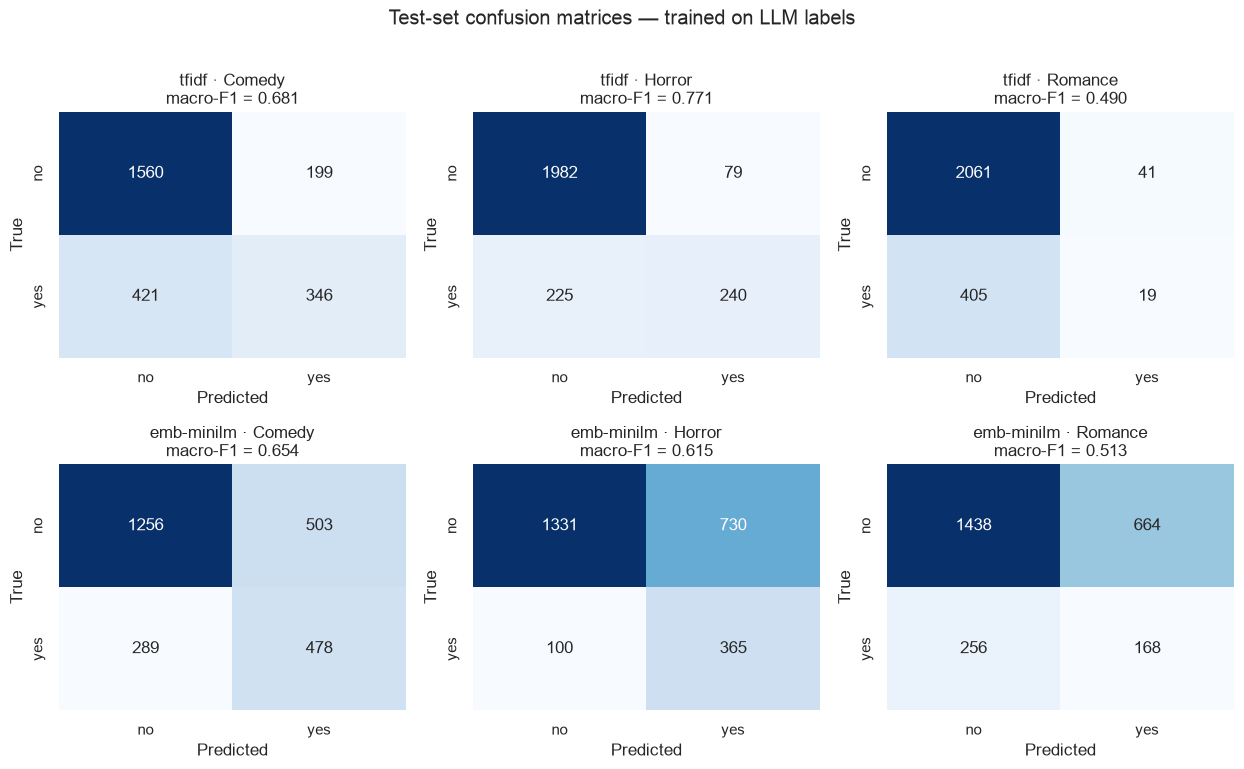

In [59]:
plot_confusions("LLM")

## 9. Leaderboard
Test-set macro-F1 for each genre and the mean across genres, ranked by the mean. The control rows are marked. The **teacher row is a reference only**: it's measured on the ≤ 300-plot training sample, not on the held-out test set, so it isn't ranked.

In [60]:
n_full, n_sample = len(train_df), len(sample)
row_names = {
    "IMDB": f"IMDB labels (full train, n={n_full:,})",
    "LLM": f"LLM labels (teacher sample, n={n_sample})",
    "IMDB-sample": f"[control] IMDB labels (teacher sample, n={n_sample})",
}

board = pd.DataFrame(
    {f"{rep} · {row_names[src]}": {g: results[(src, rep, g)]["f1"] for g in GENRES}
     for src in row_names for rep in REPS}).T
board["mean"] = board[GENRES].mean(axis=1)
board = board.sort_values("mean", ascending=False)
board.insert(0, "rank", range(1, len(board) + 1))

teacher_row = teacher_scores["macro-F1"].to_dict()
teacher_row["mean"] = np.mean(list(teacher_row.values()))
board.loc[f"REFERENCE: teacher {TEACHER_MODEL} on training sample — NOT held-out test"] = {"rank": np.nan, **teacher_row}
board

,rank,Comedy,Horror,Romance,mean
"emb-minilm · IMDB labels (full train, n=9,996)",1.0,0.757,0.827,0.742,0.775
"tfidf · IMDB labels (full train, n=9,996)",2.0,0.737,0.846,0.715,0.766
"tfidf · [control] IMDB labels (teacher sample, n=295)",3.0,0.574,0.734,0.665,0.658
"tfidf · LLM labels (teacher sample, n=295)",4.0,0.681,0.771,0.490,0.647
"emb-minilm · [control] IMDB labels (teacher sample, n=295)",5.0,0.639,0.624,0.566,0.610
"emb-minilm · LLM labels (teacher sample, n=295)",6.0,0.654,0.615,0.513,0.594
REFERENCE: teacher llama3.2:3b on training sample — NOT held-out test,NaN,0.759,0.849,0.644,0.751


In [61]:
mean_f1 = {(src, rep): board.loc[f"{rep} · {row_names[src]}", "mean"] for src in row_names for rep in REPS}
pd.DataFrame({
    rep: {
        "total loss (IMDB full → LLM sample)": mean_f1[("IMDB", rep)] - mean_f1[("LLM", rep)],
        "  from less data (IMDB full → IMDB sample)": mean_f1[("IMDB", rep)] - mean_f1[("IMDB-sample", rep)],
        "  from label noise (IMDB sample → LLM sample)": mean_f1[("IMDB-sample", rep)] - mean_f1[("LLM", rep)],
    } for rep in REPS
}).round(3)

,tfidf,emb-minilm
total loss (IMDB full → LLM sample),0.119,0.182
from less data (IMDB full → IMDB sample),0.108,0.166
from label noise (IMDB sample → LLM sample),0.011,0.016


**Discussion — how much accuracy was lost by training on the LLM's labels?**

**TODO (write after running), using the two tables above:**
- **Headline:** the drop in mean test macro-F1 from the best IMDB-label model to the best LLM-label model, in absolute points and as a percentage.
- **Breakdown:** how much of that drop comes from the teacher's label noise and how much from training on about 30× fewer plots (the control row). Usually less data is the bigger cost, which suggests that labeling more plots with the teacher would close much of the gap.
- **Representation:** does one representation hold up better on small, noisy data? Dense 384-d embeddings often do, because TF-IDF has 10,000 sparse weights to learn from only about 300 examples.
- **Teacher vs. student:** how the teacher's F1 compares to its student. Remember the teacher row is on the training sample, not the test set, and that sample is genre-enriched.
- **Bottom line:** is a cheap student taught by an LLM good enough for a deployable classifier without hand labels?

## 10. Export
Save the six **IMDB-label** models (2 representations × 3 genres), plus the fitted TF-IDF vectorizer and its scaler, which Notebook 3 needs to rebuild the exact feature space. The vectorizer's `stop_words_` attribute (every pruned term, kept only for introspection) is removed before saving, since it isn't needed for `transform` and only bloats the file.

In [62]:
MODELS_DIR.mkdir(exist_ok=True)
for rep in REPS:
    for g in GENRES:
        joblib.dump(results[("IMDB", rep, g)]["model"], MODELS_DIR / f"P3_N2_{rep}_logreg_{slug(g)}.pkl")

if hasattr(tfidf, "stop_words_"):
    del tfidf.stop_words_
joblib.dump(tfidf, MODELS_DIR / "P3_N2_tfidf_vectorizer.pkl")
joblib.dump(tfidf_scaler, MODELS_DIR / "P3_N2_tfidf_scaler.pkl")

pd.DataFrame([(p.name, f"{p.stat().st_size / 1024:.0f} KB") for p in sorted(MODELS_DIR.glob("P3_N2_*.pkl"))],
             columns=["file", "size"])

,file,size
0,P3_N2_emb-minilm_logreg_comedy.pkl,4 KB
1,P3_N2_emb-minilm_logreg_horror.pkl,4 KB
2,P3_N2_emb-minilm_logreg_romance.pkl,4 KB
3,P3_N2_tfidf_logreg_comedy.pkl,79 KB
4,P3_N2_tfidf_logreg_horror.pkl,79 KB
5,P3_N2_tfidf_logreg_romance.pkl,79 KB
6,P3_N2_tfidf_scaler.pkl,235 KB
7,P3_N2_tfidf_vectorizer.pkl,358 KB
